# US Flight Delays — Data Cleaning & Feature Engineering
**Dataset:** US Bureau of Transportation Statistics (BTS) — *Reporting Carrier On-Time Performance*, **June 2025**
Every domestic US flight operated by a major airline in the month: 611,575 flights.

Source: https://www.transtats.bts.gov · Download: `On_Time_Reporting_Carrier_On_Time_Performance_1987_present_2025_6.zip`

**Objectives**
1. Impute missing values using statistical methods
2. Detect and treat outliers (IQR / Z-score)
3. Engineer at least 3 new features

### Key columns
| Column | Meaning |
|---|---|
| FlightDate, DayOfWeek | Date of flight, 1 = Monday … 7 = Sunday |
| Reporting_Airline | Airline code (AA = American, DL = Delta, WN = Southwest, UA = United …) |
| Origin, Dest | Departure / arrival airport codes |
| CRSDepTime, CRSArrTime | **Scheduled** departure / arrival time (hhmm) |
| DepTime, ArrTime | **Actual** departure / arrival time (hhmm) |
| DepDelay, ArrDelay | Minutes late (negative = early) |
| TaxiOut, TaxiIn | Minutes taxiing on the ground |
| AirTime, Distance | Minutes in the air, miles flown |
| Cancelled, CancellationCode | 1 = cancelled; A = airline, B = weather, C = air traffic system, D = security |
| Diverted | 1 = landed at a different airport |
| CarrierDelay … LateAircraftDelay | Minutes of delay caused by each reason |

---
## Day 1 — Data Loading & Profiling

### 1. Import libraries

In [1]:
from pathlib import Path

import numpy as np                  # numerical calculations
import pandas as pd                 # tables (DataFrames)
import matplotlib.pyplot as plt     # base plotting
import seaborn as sns               # statistical charts

sns.set_theme(style="whitegrid")             # clean chart style
pd.set_option("display.max_columns", 40)     # show every column in tables

DATA = Path("data")                 # folder with the raw data
FIGS = Path("figures")              # folder for saved charts
FIGS.mkdir(exist_ok=True)           # create it if it doesn't exist

### 2. Load the data
The raw file has 110 columns; most describe diverted-flight details we don't need.
We load only the 31 columns relevant to delays.

In [2]:
cols = [
    "FlightDate", "DayOfWeek", "Reporting_Airline", "Tail_Number", "Flight_Number_Reporting_Airline",
    "Origin", "OriginCityName", "OriginState", "Dest", "DestCityName", "DestState",
    "CRSDepTime", "DepTime", "DepDelay", "TaxiOut", "TaxiIn", "CRSArrTime", "ArrTime", "ArrDelay",
    "Cancelled", "CancellationCode", "Diverted", "CRSElapsedTime", "ActualElapsedTime", "AirTime", "Distance",
    "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay",
]

df_raw = pd.read_csv(DATA / "flights_2025_06.csv", usecols=cols)   # read only the chosen columns
df = df_raw.copy()                                                  # work on a copy, keep raw untouched

print(f"{df.shape[0]:,} flights x {df.shape[1]} columns")

611,575 flights x 31 columns


In [3]:
df.head()

,DayOfWeek,FlightDate,Reporting_Airline,Tail_Number,Flight_Number_Reporting_Airline,Origin,OriginCityName,OriginState,Dest,DestCityName,DestState,CRSDepTime,DepTime,DepDelay,TaxiOut,TaxiIn,CRSArrTime,ArrTime,ArrDelay,Cancelled,CancellationCode,Diverted,CRSElapsedTime,ActualElapsedTime,AirTime,Distance,CarrierDelay,WeatherDelay,NASDelay,SecurityDelay,LateAircraftDelay
0,7,2025-06-01,AA,N106NN,1,JFK,"New York, NY",NY,LAX,"Los Angeles, CA",CA,729,718.0,-11.0,18.0,5.0,1036,951.0,-45.0,0.0,NaN,0.0,367.0,333.0,310.0,2475.0,NaN,NaN,NaN,NaN,NaN
1,1,2025-06-02,AA,N109NN,1,JFK,"New York, NY",NY,LAX,"Los Angeles, CA",CA,729,721.0,-8.0,13.0,7.0,1036,938.0,-58.0,0.0,NaN,0.0,367.0,317.0,297.0,2475.0,NaN,NaN,NaN,NaN,NaN
2,2,2025-06-03,AA,N102NN,1,JFK,"New York, NY",NY,LAX,"Los Angeles, CA",CA,729,757.0,28.0,19.0,8.0,1036,1051.0,15.0,0.0,NaN,0.0,367.0,354.0,327.0,2475.0,3.0,0.0,0.0,0.0,12.0
3,3,2025-06-04,AA,N117AN,1,JFK,"New York, NY",NY,LAX,"Los Angeles, CA",CA,729,727.0,-2.0,23.0,14.0,1036,1032.0,-4.0,0.0,NaN,0.0,367.0,365.0,328.0,2475.0,NaN,NaN,NaN,NaN,NaN
4,4,2025-06-05,AA,N102NN,1,JFK,"New York, NY",NY,LAX,"Los Angeles, CA",CA,720,714.0,-6.0,18.0,10.0,1020,1016.0,-4.0,0.0,NaN,0.0,360.0,362.0,334.0,2475.0,NaN,NaN,NaN,NaN,NaN


### 3. Data types and non-null counts

In [4]:
df.info(memory_usage="deep")    # dtype + non-null count per column

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 611575 entries, 0 to 611574
Data columns (total 31 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   DayOfWeek                        611575 non-null  int64  
 1   FlightDate                       611575 non-null  object 
 2   Reporting_Airline                611575 non-null  object 
 3   Tail_Number                      610654 non-null  object 
 4   Flight_Number_Reporting_Airline  611575 non-null  int64  
 5   Origin                           611575 non-null  object 
 6   OriginCityName                   611575 non-null  object 
 7   OriginState                      611575 non-null  object 
 8   Dest                             611575 non-null  object 
 9   DestCityName                     611575 non-null  object 
 10  DestState                        611575 non-null  object 
 11  CRSDepTime                       611575 non-null  int64  
 12  De

### 4. Missing values
Kit rule: **< 5%** drop / mode fill · **5–20%** median or group-wise · **> 20%** KNN or indicator feature

In [5]:
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),                       # count of empty cells
    "pct_missing": (df.isna().mean() * 100).round(2),   # share of empty cells in %
}).query("n_missing > 0").sort_values("pct_missing", ascending=False)


def kit_rule(pct):                      # map % missing to the kit's strategy
    if pct < 5:
        return "< 5%: drop rows or simple fill"
    if pct <= 20:
        return "5-20%: median / group-wise"
    return "> 20%: KNN or indicator feature"


missing["kit_rule"] = missing["pct_missing"].apply(kit_rule)
missing

,n_missing,pct_missing,kit_rule
CancellationCode,601839,98.41,> 20%: KNN or indicator feature
NASDelay,442170,72.30,> 20%: KNN or indicator feature
SecurityDelay,442170,72.30,> 20%: KNN or indicator feature
LateAircraftDelay,442170,72.30,> 20%: KNN or indicator feature
WeatherDelay,442170,72.30,> 20%: KNN or indicator feature
CarrierDelay,442170,72.30,> 20%: KNN or indicator feature
ActualElapsedTime,12103,1.98,< 5%: drop rows or simple fill
ArrDelay,12103,1.98,< 5%: drop rows or simple fill
AirTime,12103,1.98,< 5%: drop rows or simple fill
TaxiIn,9913,1.62,< 5%: drop rows or simple fill


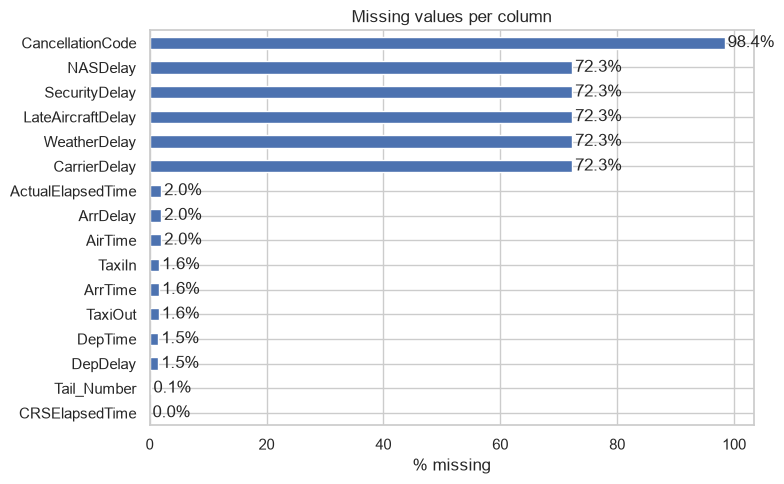

In [6]:
ax = missing["pct_missing"].plot.barh(color="#4C72B0", figsize=(8, 5))
ax.invert_yaxis()                                   # largest at the top
ax.set_xlabel("% missing")
ax.set_title("Missing values per column")
for i, v in enumerate(missing["pct_missing"]):      # write the % next to each bar
    ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
plt.tight_layout()
plt.savefig(FIGS / "flights_01_missing_values.png", dpi=150)
plt.show()

### 5. Why are values missing?
Before imputing, check whether the gaps have a **real-world reason**. If they do, filling them
with a mean or median would be wrong.

In [7]:
# Are the missing departure delays the cancelled flights?
pd.crosstab(df["Cancelled"], df["DepDelay"].isna(),
            rownames=["Cancelled"], colnames=["DepDelay missing"])

DepDelay missing,False,True
Cancelled,,
0.0,601839,0
1.0,534,9202


In [8]:
# Are the missing arrival delays the cancelled or diverted flights?
not_completed = (df["Cancelled"] == 1) | (df["Diverted"] == 1)

pd.crosstab(not_completed, df["ArrDelay"].isna(),
            rownames=["Cancelled or diverted"], colnames=["ArrDelay missing"])

ArrDelay missing,False,True
Cancelled or diverted,,
False,599472,0
True,0,12103


In [9]:
# BTS only records delay causes for flights arriving 15+ minutes late
late_15 = df["ArrDelay"] >= 15

pd.crosstab(late_15, df["CarrierDelay"].isna(),
            rownames=["Arrived 15+ min late"], colnames=["Delay causes missing"])

Delay causes missing,False,True
Arrived 15+ min late,,
False,0,442170
True,169405,0


In [10]:
# CancellationCode should only exist for cancelled flights
pd.crosstab(df["Cancelled"], df["CancellationCode"].isna(),
            rownames=["Cancelled"], colnames=["CancellationCode missing"])

CancellationCode missing,False,True
Cancelled,,
0.0,0,601839
1.0,9736,0


In [11]:
# Missing tail numbers (aircraft ID): which flights are they?
df.loc[df["Tail_Number"].isna(), "Cancelled"].value_counts()

Cancelled
1.0    921
Name: count, dtype: int64

### 6. Descriptive statistics
Mean far above the median → right-skewed → median is the safer "typical" value and outliers are likely.

In [12]:
num_cols = ["DepDelay", "ArrDelay", "TaxiOut", "TaxiIn", "AirTime", "Distance",
            "CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]

desc = df[num_cols].describe().T            # count, mean, std, min, quartiles, max
desc["median"] = df[num_cols].median()
desc["skew"] = df[num_cols].skew()          # 0 = symmetric, > 1 = strongly right-skewed
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,median,skew
DepDelay,602373.0,19.29,64.93,-52.0,-5.0,-1.0,18.0,2810.0,-1.0,8.89
ArrDelay,599472.0,15.59,67.02,-78.0,-13.0,-3.0,19.0,2794.0,-3.0,8.17
TaxiOut,601889.0,18.64,11.11,1.0,12.0,16.0,21.0,177.0,16.0,3.78
TaxiIn,601662.0,8.95,8.21,1.0,5.0,7.0,10.0,355.0,7.0,5.74
AirTime,599472.0,117.22,71.28,8.0,64.0,100.0,147.0,643.0,100.0,1.30
Distance,611575.0,852.19,607.82,31.0,404.0,693.0,1088.0,5095.0,693.0,1.38
CarrierDelay,169405.0,24.18,75.19,0.0,0.0,2.0,21.0,2794.0,2.0,9.94
WeatherDelay,169405.0,5.27,34.74,0.0,0.0,0.0,0.0,1458.0,0.0,15.71
NASDelay,169405.0,15.98,36.59,0.0,0.0,1.0,18.0,1327.0,1.0,8.17
SecurityDelay,169405.0,0.12,4.06,0.0,0.0,0.0,0.0,766.0,0.0,95.98


In [13]:
df.describe(include="object").T     # text columns: count, unique values, most frequent

,count,unique,top,freq
FlightDate,611575,30,2025-06-27,21460
Reporting_Airline,611575,14,WN,122348
Tail_Number,610654,5651,N490HA,292
Origin,611575,345,ORD,29641
OriginCityName,611575,339,"Chicago, IL",36828
OriginState,611575,52,TX,66296
Dest,611575,345,ORD,29630
DestCityName,611575,339,"Chicago, IL",36814
DestState,611575,52,TX,66277
CancellationCode,9736,3,B,5636


### 7. Duplicates

In [14]:
print("Exact duplicate rows:", df.duplicated().sum())

# the same flight number, airline, date and origin should appear only once
key = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline", "Origin"]
print("Duplicate flight keys:", df.duplicated(subset=key).sum())

Exact duplicate rows: 0
Duplicate flight keys: 0


### 8. Distributions

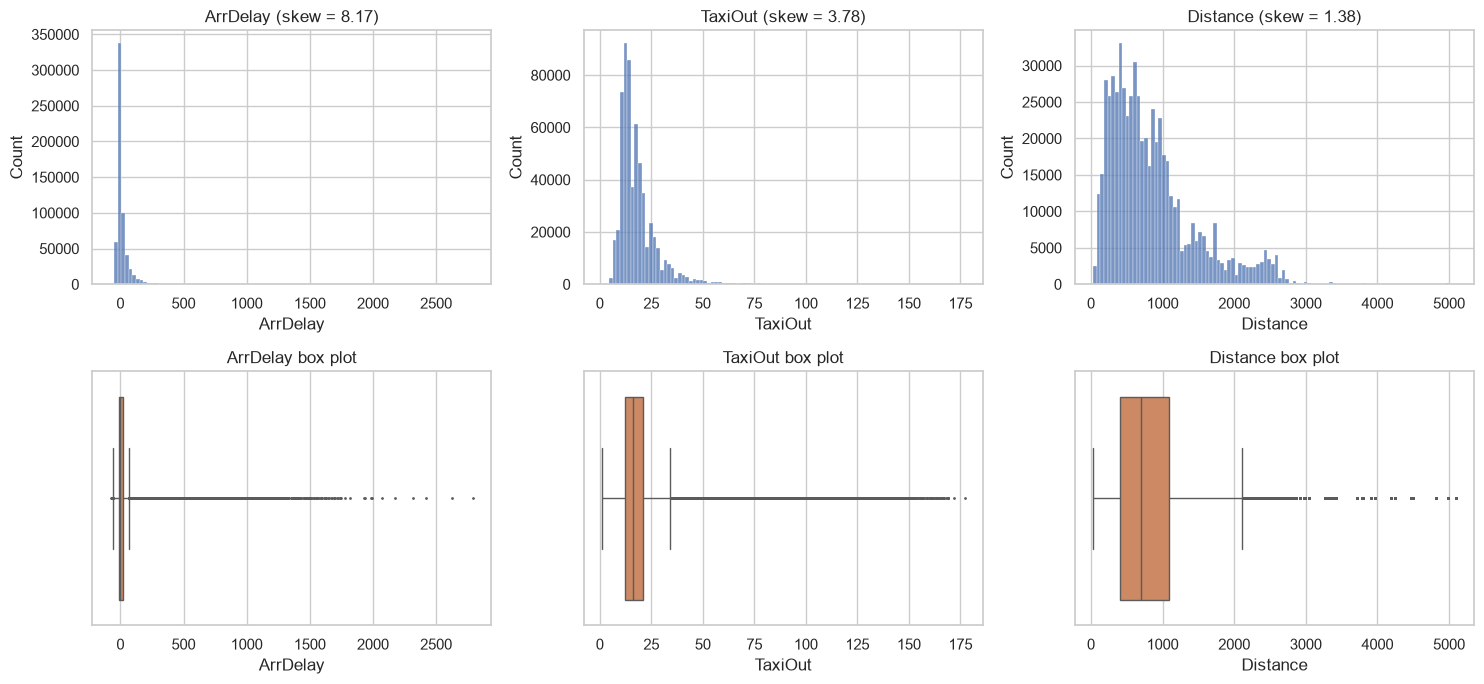

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))

for col, (ax_h, ax_b) in zip(["ArrDelay", "TaxiOut", "Distance"], axes.T):
    sns.histplot(df[col].dropna(), bins=100, ax=ax_h, color="#4C72B0")     # shape of the data
    ax_h.set_title(f"{col} (skew = {df[col].skew():.2f})")
    sns.boxplot(x=df[col], ax=ax_b, color="#DD8452", fliersize=1)          # dots = possible outliers
    ax_b.set_title(f"{col} box plot")

plt.tight_layout()
plt.savefig(FIGS / "flights_02_distributions.png", dpi=150)
plt.show()

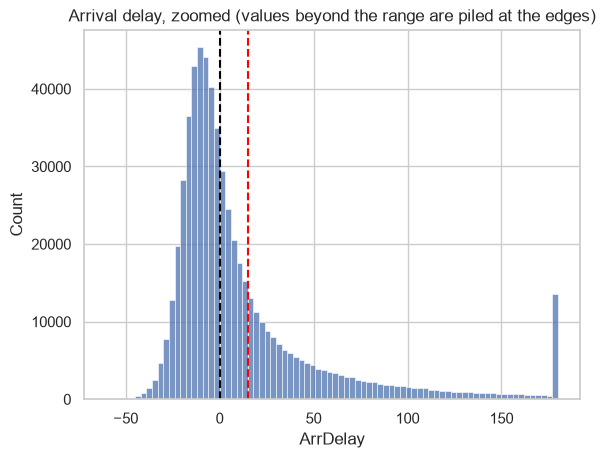

In [16]:
# Zoom in: arrival delays between -60 and +180 minutes
ax = sns.histplot(df["ArrDelay"].clip(-60, 180), bins=80, color="#4C72B0")
ax.axvline(0, color="black", ls="--")       # left of the line = arrived early
ax.axvline(15, color="red", ls="--")        # BTS definition of "delayed": 15+ minutes
ax.set_title("Arrival delay, zoomed (values beyond the range are piled at the edges)")
plt.savefig(FIGS / "flights_03_arrdelay_zoom.png", dpi=150)
plt.show()

### 9. Outlier detection — IQR rule
Lower = Q1 − 1.5·IQR  Upper = Q3 + 1.5·IQR  (detection only; treatment comes on Day 3)

In [17]:
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])     # 25th and 75th percentiles
    iqr = q3 - q1                          # spread of the middle 50%
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr


rows = []
for col in ["DepDelay", "ArrDelay", "TaxiOut", "TaxiIn", "AirTime", "Distance"]:
    lo, hi = iqr_bounds(df[col].dropna())
    n_out = ((df[col] < lo) | (df[col] > hi)).sum()          # values outside the bounds
    rows.append({"column": col, "lower": lo, "upper": hi,
                 "n_outliers": n_out, "pct": n_out / df[col].notna().sum() * 100})

outliers = pd.DataFrame(rows).set_index("column").round(2)
outliers

,lower,upper,n_outliers,pct
column,,,,
DepDelay,-39.5,52.5,74242,12.32
ArrDelay,-61.0,67.0,59522,9.93
TaxiOut,-1.5,34.5,37914,6.30
TaxiIn,-2.5,17.5,51130,8.50
AirTime,-60.5,271.5,31115,5.19
Distance,-622.0,2114.0,36490,5.97


In [18]:
# The 10 most extreme arrival delays: errors or real events?
df.nlargest(10, "ArrDelay")[["FlightDate", "Reporting_Airline", "Origin", "Dest",
                             "DepDelay", "ArrDelay", "CarrierDelay", "WeatherDelay", "LateAircraftDelay"]]

,FlightDate,Reporting_Airline,Origin,Dest,DepDelay,ArrDelay,CarrierDelay,WeatherDelay,LateAircraftDelay
70850,2025-06-27,AA,SJU,MIA,2810.0,2794.0,2794.0,0.0,0.0
81497,2025-06-19,AA,SLC,PHX,2613.0,2628.0,2601.0,0.0,12.0
163343,2025-06-01,OH,CRW,DCA,2440.0,2420.0,2420.0,0.0,0.0
11001,2025-06-28,AA,RIC,CLT,2297.0,2318.0,1946.0,0.0,351.0
5046,2025-06-24,AA,MSY,DFW,2164.0,2172.0,1694.0,0.0,470.0
3330,2025-06-16,AA,ANC,DFW,2083.0,2070.0,1830.0,0.0,240.0
75397,2025-06-09,AA,IAH,CLT,2023.0,1995.0,14.0,0.0,1981.0
16122,2025-06-30,AA,IAH,DFW,1999.0,1984.0,1984.0,0.0,0.0
222067,2025-06-06,OO,CLE,ORD,1909.0,1939.0,1909.0,0.0,0.0
2799,2025-06-10,AA,ANC,ORD,1920.0,1928.0,780.0,0.0,1140.0


### 10. Categorical overview

In [19]:
airline = df.groupby("Reporting_Airline").agg(
    flights=("Cancelled", "size"),                          # number of flights
    cancel_rate=("Cancelled", "mean"),                      # share cancelled
    median_arr_delay=("ArrDelay", "median"),                # typical arrival delay
    pct_late_15=("ArrDelay", lambda s: (s >= 15).mean()),   # share arriving 15+ min late
).sort_values("flights", ascending=False)

airline[["cancel_rate", "pct_late_15"]] *= 100              # convert to %
airline.round(2)

,flights,cancel_rate,median_arr_delay,pct_late_15
Reporting_Airline,,,,
WN,122348,0.62,-1.0,27.88
DL,91122,1.72,-5.0,25.61
AA,85419,2.45,-1.0,31.86
OO,73660,0.80,-4.0,24.71
UA,66324,0.66,-4.0,26.12
YX,28872,4.39,-6.0,24.94
MQ,26837,1.71,-2.0,26.43
AS,22576,0.77,1.0,30.00
OH,21161,6.89,1.0,33.78


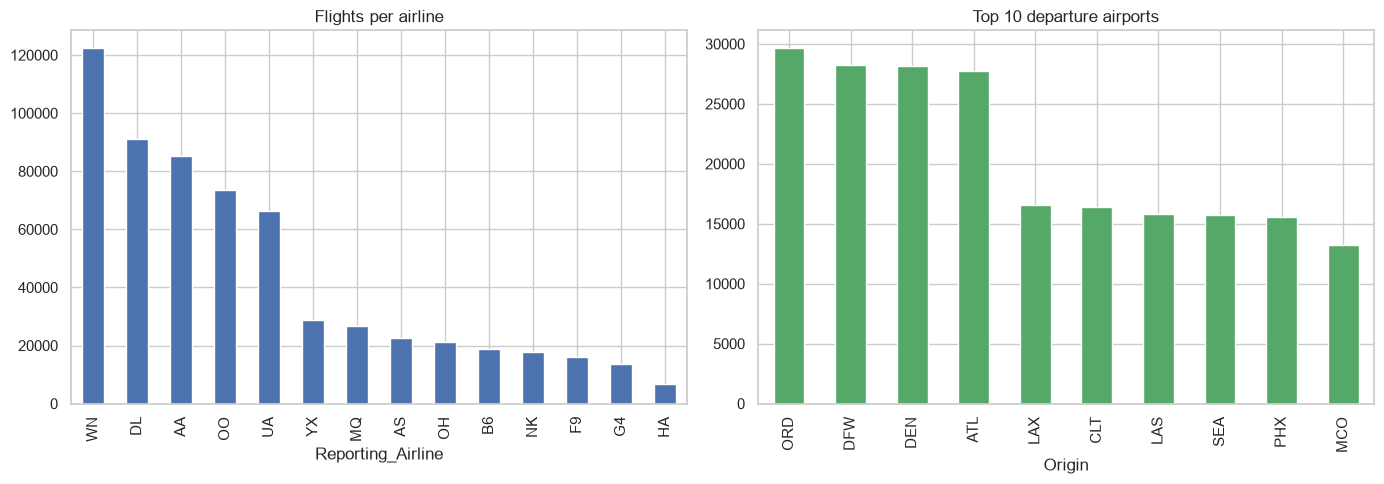

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

airline["flights"].plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Flights per airline")

df["Origin"].value_counts().head(10).plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("Top 10 departure airports")

plt.tight_layout()
plt.savefig(FIGS / "flights_04_airlines_airports.png", dpi=150)
plt.show()

In [21]:
# Cancellation reasons: A = airline, B = weather, C = air traffic system, D = security
df["CancellationCode"].value_counts()

CancellationCode
B    5636
A    2432
C    1668
Name: count, dtype: int64

---
## Day 1 Findings

**Data quality**
- 611,575 flights, 31 columns kept, **no duplicate rows or duplicate flights**.
- **Every missing value has a real-world reason.** None are random:

| Column(s) | % missing | Reason (verified with crosstabs) | Plan for Day 2 |
|---|---|---|---|
| CarrierDelay … LateAircraftDelay | 72.3% | Recorded only for flights arriving 15+ min late | Fill with **0** (no delay = 0 minutes) |
| CancellationCode | 98.4% | Exists only for cancelled flights | Fill with `"Not cancelled"` |
| DepTime, DepDelay, TaxiOut | ~1.5% | Cancelled flights never departed | Keep as missing; exclude cancelled flights from delay analysis |
| ArrTime, ArrDelay, AirTime, TaxiIn | ~2% | Cancelled (9,736) or diverted (2,367) flights | Same as above |
| Tail_Number | 0.15% | All 921 are cancelled flights | Fill with `"Unknown"` |
| CRSElapsedTime | 2 rows | Scheduled duration missing | **Group-wise median** of the same route |

- Because the real gaps are explained, the statistical imputation requirement (mean vs median vs KNN) will be shown with a
  **validation experiment**: hide 20% of known `TaxiOut` values, impute them with each method, and compare against the true values.

**Outliers**
- Delays are extremely right-skewed: mean arrival delay **15.6 min** vs median **−3 min** (skew 8.2). The worst is **2,794 min (46.6 h)**.
- The extreme delays are **real events, not errors**: each has a recorded cause (mostly airline-caused).
  So they will be **capped (winsorized), not deleted**.
- The IQR rule flags 10–12% of delays, which is too aggressive for heavy-tailed data. Day 3 will compare IQR with percentile capping.
- Long distances (> 2,114 miles, e.g. flights to Hawaii) are genuine routes, so they will be kept.

**Business context**
- 14 airlines; Southwest (WN) is the largest with 122k flights.
- About 28% of completed flights arrived 15+ minutes late. Frontier (F9) was worst at 37%; Hawaiian (HA) was best at 18%.
- 1.6% of flights were cancelled. **Weather (B) caused 58%** of cancellations.

---
## Day 2 — Missing Value Imputation

### 11. Fill the gaps that have a known reason
These values are missing **because of what happened to the flight**, so the reason gives the correct fill.

In [22]:
delay_causes = ["CarrierDelay", "WeatherDelay", "NASDelay", "SecurityDelay", "LateAircraftDelay"]
df[delay_causes] = df[delay_causes].fillna(0)                        # not 15+ min late -> 0 minutes of each cause
df["CancellationCode"] = df["CancellationCode"].fillna("Not cancelled")
df["Tail_Number"] = df["Tail_Number"].fillna("Unknown")              # all are cancelled flights

# CRSElapsedTime: group-wise median = typical scheduled duration of the same route
route_median = df.groupby(["Origin", "Dest"])["CRSElapsedTime"].transform("median")
df["CRSElapsedTime"] = df["CRSElapsedTime"].fillna(route_median)

df.isna().sum()[lambda s: s > 0]      # what is still missing?

DepTime               9172
DepDelay              9202
TaxiOut               9686
TaxiIn                9913
ArrTime               9913
ArrDelay             12103
ActualElapsedTime    12103
AirTime              12103
dtype: int64

The gaps left are the times and delays of **cancelled or diverted** flights. Those flights never departed or
never arrived, so there is no true value to fill. We keep them as missing and study delays on **completed flights**.

In [23]:
completed = (df["Cancelled"] == 0) & (df["Diverted"] == 0)
flights = df[completed].copy()               # flights that departed and arrived as planned

print(f"Completed flights: {len(flights):,} of {len(df):,}")
print("Missing values left:", flights.isna().sum().sum())

Completed flights: 599,472 of 611,575


Missing values left: 0


### 12. Experiment: Mean vs Median vs Group-wise median vs KNN
Our real gaps are explained, so to compare the statistical methods we **create artificial gaps**:
hide 20% of known `TaxiOut` values, fill them with each method, and compare with the true values.

- **MAE** = average error in minutes (lower is better)
- **Std** = spread of the column after filling (closer to the true std = distribution preserved)

In [24]:
from sklearn.impute import KNNImputer

sample = flights.sample(10_000, random_state=42).reset_index(drop=True)   # KNN is slow, so use a sample
sample["dep_hour"] = sample["CRSDepTime"] // 100 % 24
sample["origin_flights"] = sample["Origin"].map(df["Origin"].value_counts())   # airport size

rng = np.random.default_rng(42)
hide = rng.random(len(sample)) < 0.20        # choose 20% of rows to hide
truth = sample.loc[hide, "TaxiOut"]
test = sample.copy()
test.loc[hide, "TaxiOut"] = np.nan

results = {
    "Mean": test["TaxiOut"].fillna(test["TaxiOut"].mean()),
    "Median": test["TaxiOut"].fillna(test["TaxiOut"].median()),
    "Group median (by airport)": test["TaxiOut"]
        .fillna(test.groupby("Origin")["TaxiOut"].transform("median"))
        .fillna(test["TaxiOut"].median()),                           # airports with no known value
}

# KNN: find the 5 most similar flights (hour, distance, airport size, taxi-in) and average their TaxiOut
knn_cols = ["TaxiOut", "dep_hour", "Distance", "origin_flights", "TaxiIn"]
X = test[knn_cols]
X_scaled = (X - X.mean()) / X.std()          # same scale for every feature; NaN stays NaN
filled = KNNImputer(n_neighbors=5).fit_transform(X_scaled)
results["KNN (k=5)"] = pd.Series(filled[:, 0] * X["TaxiOut"].std() + X["TaxiOut"].mean())

summary = pd.DataFrame({
    name: {"MAE (min)": (s[hide] - truth).abs().mean(), "Std after filling": s.std()}
    for name, s in results.items()
}).T
summary.loc["True data"] = [0, sample["TaxiOut"].std()]
summary.round(2)

,MAE (min),Std after filling
Mean,7.11,9.81
Median,6.66,9.87
Group median (by airport),5.96,10.00
KNN (k=5),7.25,10.16
True data,0.00,11.17


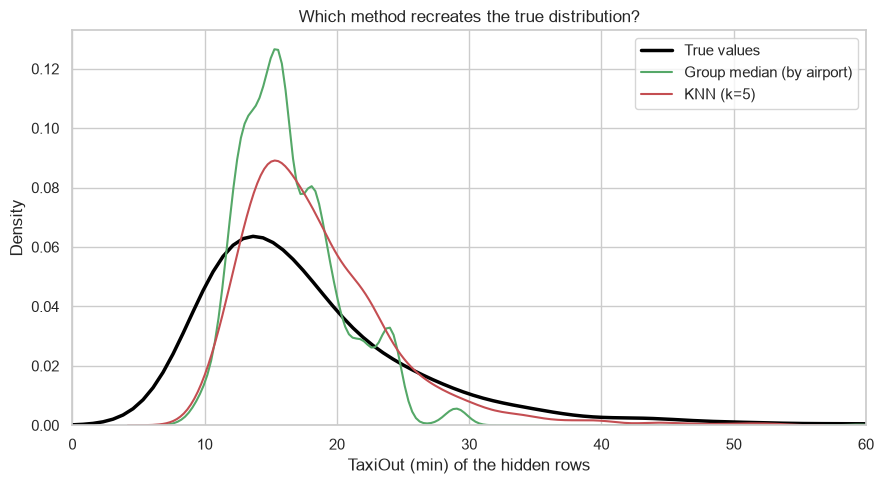

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.kdeplot(truth, ax=ax, color="black", lw=2.5, label="True values")
for name, s in results.items():
    sns.kdeplot(s[hide], ax=ax, label=name, warn_singular=False)
ax.set_xlim(0, 60)
ax.set_xlabel("TaxiOut (min) of the hidden rows")
ax.set_title("Which method recreates the true distribution?")
ax.legend()
plt.tight_layout()
plt.savefig(FIGS / "flights_05_imputation_comparison.png", dpi=150)
plt.show()

---
## Day 3 — Outlier Treatment & Feature Engineering
### 13. Detect outliers: IQR vs Z-score

In [26]:
out_cols = ["DepDelay", "ArrDelay", "TaxiOut", "TaxiIn"]

rows = []
for col in out_cols:
    s = flights[col]
    lo, hi = iqr_bounds(s)
    z = (s - s.mean()) / s.std()                    # Z-score: how many std away from the mean
    rows.append({"column": col,
                 "IQR upper bound": hi, "IQR flagged %": ((s < lo) | (s > hi)).mean() * 100,
                 "Z upper bound": s.mean() + 3 * s.std(), "Z flagged %": (z.abs() > 3).mean() * 100})

pd.DataFrame(rows).set_index("column").round(2)

,IQR upper bound,IQR flagged %,Z upper bound,Z flagged %
column,,,,
DepDelay,52.5,12.26,213.48,1.47
ArrDelay,67.0,9.93,216.66,1.44
TaxiOut,34.5,6.28,51.88,1.86
TaxiIn,17.5,8.47,33.41,1.79


**Choice: Z-score capping (mean ± 3 std).** IQR flags ~10% of delays and would cap arrival delays at 67 minutes,
erasing real information about late flights. Z-score flags only ~1.5% and caps at ~217 minutes. The extreme delays are real events (Day 1), so we **cap** them at the
Z-score bound instead of deleting rows. No flight is lost.

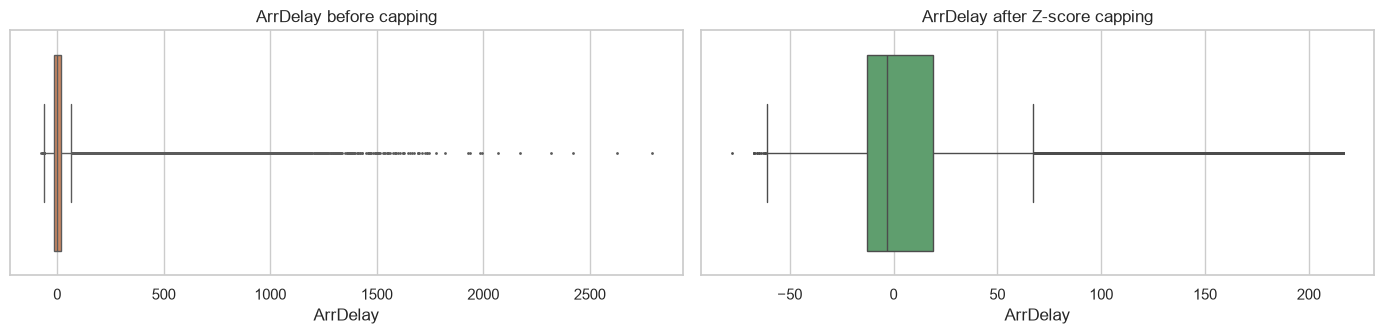

Max ArrDelay: 2,794 -> 217 min
Rows capped: 8,648 (1.4%)


In [27]:
flights["is_delayed"] = (flights["ArrDelay"] >= 15).astype(int)   # target, created before capping

before = flights["ArrDelay"].copy()
for col in out_cols:
    s = flights[col]
    flights[col] = s.clip(s.mean() - 3 * s.std(), s.mean() + 3 * s.std())

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5), sharex=False)
sns.boxplot(x=before, ax=axes[0], color="#DD8452", fliersize=1).set_title("ArrDelay before capping")
sns.boxplot(x=flights["ArrDelay"], ax=axes[1], color="#55A868", fliersize=1).set_title("ArrDelay after Z-score capping")
plt.tight_layout()
plt.savefig(FIGS / "flights_06_outlier_capping.png", dpi=150)
plt.show()

print(f"Max ArrDelay: {before.max():,.0f} -> {flights['ArrDelay'].max():,.0f} min")
print(f"Rows capped: {(before != flights['ArrDelay']).sum():,} ({(before != flights['ArrDelay']).mean():.1%})")

### 14. Engineer new features
Only information known **before take-off** is used, so a model could use these in real life (no data leakage).

| Feature | From | Why it may predict delays |
|---|---|---|
| `dep_hour` | CRSDepTime | Delays build up during the day |
| `time_of_day` | dep_hour | Morning / Afternoon / Evening / Night |
| `is_weekend` | DayOfWeek | Different traffic on weekends |
| `aircraft_leg` | Tail_Number + date + time | 1st, 2nd, 3rd… flight of that plane today; late planes pass delays on |
| `origin_flights` | Origin | Airport size: busy hubs are more congested |
| `route` | Origin + Dest | Some routes are delay-prone |

In [28]:
flights["dep_hour"] = flights["CRSDepTime"] // 100 % 24           # 1945 -> 19, 2400 -> 0
flights["time_of_day"] = pd.cut(flights["dep_hour"], bins=[-1, 5, 11, 17, 23],
                                labels=["Night", "Morning", "Afternoon", "Evening"])
flights["is_weekend"] = (flights["DayOfWeek"] >= 6).astype(int)    # 6 = Saturday, 7 = Sunday
flights["route"] = flights["Origin"] + "-" + flights["Dest"]
flights["origin_flights"] = flights["Origin"].map(df["Origin"].value_counts())

# Order of each flight in its aircraft's day, from the schedule (cancelled flights included)
leg = (df.sort_values(["Tail_Number", "FlightDate", "CRSDepTime"])
         .groupby(["Tail_Number", "FlightDate"]).cumcount() + 1)
flights["aircraft_leg"] = leg.reindex(flights.index)

new_features = ["dep_hour", "time_of_day", "is_weekend", "aircraft_leg", "origin_flights", "route"]
flights[new_features + ["is_delayed"]].head()

,dep_hour,time_of_day,is_weekend,aircraft_leg,origin_flights,route,is_delayed
0,7,Morning,1,1,8848,JFK-LAX,0
1,7,Morning,0,1,8848,JFK-LAX,0
2,7,Morning,0,1,8848,JFK-LAX,1
3,7,Morning,0,1,8848,JFK-LAX,0
4,7,Morning,0,1,8848,JFK-LAX,0


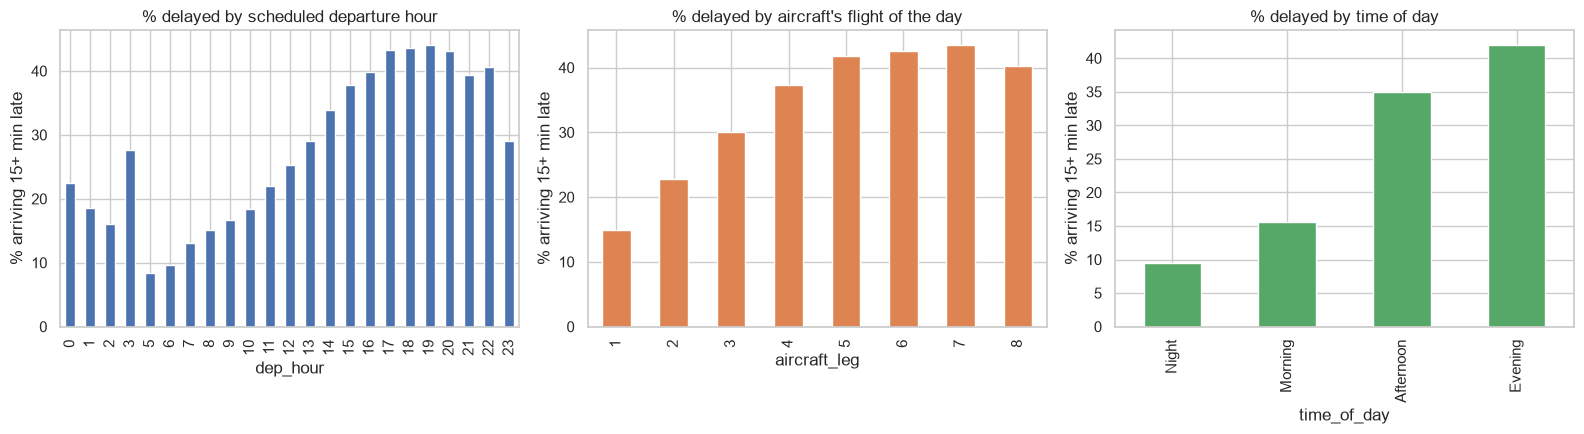

is_weekend
Weekday    28.0
Weekend    28.8
Name: is_delayed, dtype: float64

In [29]:
# Do the new features actually separate delayed from on-time flights?
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

(flights.groupby("dep_hour")["is_delayed"].mean() * 100).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("% delayed by scheduled departure hour")

(flights[flights["aircraft_leg"] <= 8].groupby("aircraft_leg")["is_delayed"].mean() * 100).plot.bar(ax=axes[1], color="#DD8452")
axes[1].set_title("% delayed by aircraft's flight of the day")

(flights.groupby("time_of_day", observed=True)["is_delayed"].mean() * 100).plot.bar(ax=axes[2], color="#55A868")
axes[2].set_title("% delayed by time of day")

for ax in axes:
    ax.set_ylabel("% arriving 15+ min late")
plt.tight_layout()
plt.savefig(FIGS / "flights_07_new_features.png", dpi=150)
plt.show()

flights.groupby("is_weekend")["is_delayed"].mean().mul(100).round(1).rename(index={0: "Weekday", 1: "Weekend"})

### 15. Save the clean dataset

In [30]:
flights.to_csv(DATA / "flights_2025_06_clean.csv", index=False)
print(f"Saved {flights.shape[0]:,} flights x {flights.shape[1]} columns")
print("Missing values:", flights.isna().sum().sum())

Saved 599,472 flights x 38 columns


Missing values: 0


---
## Final Summary — Project 1

**1. Missing values (statistical imputation)**
- Every gap had a real-world reason, so reason-based fills were used: delay causes → 0, CancellationCode → "Not cancelled", Tail_Number → "Unknown", CRSElapsedTime → **group-wise median** of the route.
- Cancelled / diverted flights (12,103) never completed, so delays were studied on the **599,472 completed flights**, which have **0 missing values**.
- Experiment (20% of TaxiOut hidden): **group-wise median was most accurate (MAE 5.96 min)**, beating median (6.66), mean (7.11) and KNN (7.25). KNN preserved the spread best (std 10.16 vs true 11.17). Every method shrinks the spread, so imputing real data needs care.

**2. Outliers (IQR vs Z-score)**
- IQR flagged 10–12% of delays (cap at 67 min): too aggressive for heavy-tailed data.
- **Z-score capping (mean ± 3 std)** was used: 8,648 flights (1.4%) capped, max arrival delay 2,794 → 217 min. No rows deleted.

**3. New features (6, all known before take-off)**
- `dep_hour`: delays rise from **8% at 5 am to 44% at 7 pm**.
- `aircraft_leg`: a plane's 1st flight of the day is late **15%** of the time, its 5th+ flight **42%+**. Delays chain through the day.
- `time_of_day`: Morning 16% vs Evening 42% delayed.
- `is_weekend`, `origin_flights` (airport size), `route`.
- Target `is_delayed` (arrived 15+ min late): 28.3% of flights.

**Output:** `data/flights_2025_06_clean.csv`: 599,472 flights × 38 columns, ready for machine learning.
